# Stage 2: Face CNN and localised Chebyshev graph convolution

This experiment combines surface geometry with graph convolution for classifying
B-rep faces. A Face CNN represents each face's surface grid, and a Chebyshev
polynomial filter incorporates information from neighbouring faces. A pointwise
two-layer classifier produces one class prediction per face.

The experiment is organised into six sections:

1. [Setup and configuration](#1-setup-and-configuration)
2. [Data pipeline](#2-data-pipeline)
3. [Model](#3-model)
4. [Training pipeline](#4-training-pipeline)
5. [Evaluation pipeline](#5-evaluation-pipeline)
6. [Results and plots](#6-results-and-plots)

We retain the complete official dataset partitions, with the following roles:

| Split | Role in the experiment |
| --- | --- |
| `train` | Parameter optimisation and assessment of the final training fit |
| `validation` | Monitoring loss and accuracy after each epoch and evaluating the final model |
| `test` | Assessing the final model on held-out data after training |

The reported model is taken from the final configured epoch. Test scores are
excluded from training and checkpoint selection. All solids, faces, and final
partial batches are included. The **gnn_project** kernel is used, with sections
executed in order.

Each model has one graph convolution with a two-hop or three-hop graph receptive
field. Face outputs are retained throughout; no graph coarsening or global pooling
is applied. Edge geometry and shallow topology descriptors are not inputs to this model.

## 1. Setup and configuration

The default configuration uses frozen geometry embeddings, a three-hop filter,
graph width 64, and 20 training epochs. Adam uses a learning rate of 0.001,
with batches of 128 solids. The number of faces therefore varies between batches.

Both frozen and joint modes start from the same completed geometry encoder
checkpoint. Each hop count and mode has a separate results directory. A fixed
seed and deterministic settings support reproducibility. Repeated runs replace
result files with the same names.

The parameter `cheb_hops` is the polynomial degree. Degrees two and three use
three and four terms, respectively, including the zero-order term.

In [55]:
import os
os.environ["DGLBACKEND"] = "pytorch"

import csv
import hashlib
import json

import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from uvnet_project.checkpointing import seed_everything, save_training_checkpoint, load_training_checkpoint
from uvnet_project.face_cnn import FaceCNN
from uvnet_project.chebyshev import scaled_laplacian, collate_cheb, ChebFaceClassifier
from uvnet_project.load_mfcad import DATA_DIR, _load_sample, _load_splits
from uvnet_project.evaluation import evaluate

In [56]:
seed = 0
deterministic = True
# Set a completed Chebyshev checkpoint to resume, then rerun preparation cells.
# resume_checkpoint = DATA_DIR.parent.parent / "results/cheb2_frozen_run_01/epoch_010/checkpoint.pt"
resume_checkpoint = None
seed_everything(seed, deterministic=deterministic)

project_dir = DATA_DIR.parent.parent
baseline_checkpoint = project_dir / "results/baseline_run_01/epoch_020/checkpoint.pt"
training_mode = "joint"  # "frozen" or "joint"
cheb_hops = 3  # polynomial degree: 2 or 3; number of terms is degree + 1
graph_dim = 64  # output width of the graph convolution
num_epochs = 20
batch_size = 128  # solids per batch
learning_rate = 0.001
run_dir = project_dir / "results" / f"cheb{cheb_hops}_{training_mode}_run_01"
cache_dir = project_dir / "data/feature_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if training_mode not in ("frozen", "joint") or cheb_hops not in (2, 3):
    raise ValueError("Choose frozen/joint and cheb_hops=2 or 3.")
if min(num_epochs, batch_size) < 1:
    raise ValueError("Epoch count and batch size must be positive.")

SPLITS = ("train", "validation", "test")
print("Device:", device, "Mode:", training_mode, "Chebyshev hops:", cheb_hops)

Device: cuda Mode: joint Chebyshev hops: 3


### 1.1 Pretrained geometry encoder

The geometry checkpoint supplies the encoder dimensions, initial CNN weights,
and classifier hidden width. Its hash identifies the source weights in feature
caches and training checkpoints.

A fixed encoder prepares cached embeddings for frozen mode. Joint mode creates
a separate trainable encoder from the same initial weights. The default geometry
embedding has 64 dimensions and the classifier predicts 16 face classes.

In [57]:
if not baseline_checkpoint.is_file():
    raise FileNotFoundError(f"The pretrained geometry checkpoint is required: {baseline_checkpoint}")
checkpoint = torch.load(baseline_checkpoint, map_location="cpu", weights_only=True)
config = checkpoint["config"]
embedding_dim, hidden_dim = config["embedding_dim"], config["hidden_dim"]
num_classes, in_channels = config["num_classes"], config["in_channels"]
baseline_hash = hashlib.sha256(baseline_checkpoint.read_bytes()).hexdigest()
cnn_state = {key.removeprefix("0."): value for key, value in checkpoint["model_state_dict"].items()
             if key.startswith("0.")}
face_cnn = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
face_cnn.load_state_dict(cnn_state, strict=True)
face_cnn.requires_grad_(False)
face_cnn = face_cnn.to(device).eval()

## 2. Data pipeline

### 2.1 Dataset partitions

Sample IDs are read from the official split file. Each partition is checked for
empty or duplicate entries and overlap with the other partitions. Original
sample order is retained for indexed prediction export.

In [58]:
official_splits = _load_splits()
split_ids = {}
seen_ids = set()
for split in SPLITS:
    ids = list(official_splits[split])
    if not ids:
        raise ValueError(f"The {split} split is empty.")
    if len(ids) != len(set(ids)):
        raise ValueError(f"Duplicate sample IDs in {split}.")
    overlap = seen_ids.intersection(ids)
    if overlap:
        raise ValueError(f"The {split} split overlaps an earlier split: {sorted(overlap)[:5]}")
    split_ids[split] = ids
    seen_ids.update(ids)

display(pd.DataFrame([
    {"split": split, "solids": len(split_ids[split])}
    for split in SPLITS
]).set_index("split"))
print("All three official splits are non-empty, unique, and disjoint.")

,solids
split,
train,9277
validation,3090
test,3094


All three official splits are non-empty, unique, and disjoint.


### 2.2 Sparse graph operators and geometry inputs

Each solid is represented by a simple undirected graph. Self-loops are removed,
parallel edges are collapsed, and adjacency is made symmetric. The normalised
Laplacian is `L = I - D^(-1/2) A D^(-1/2)`. Using the spectral upper bound
`lambda_max = 2` gives the scaled operator
`L_tilde = L - I = -D^(-1/2) A D^(-1/2)`.

An isolated face has a zero row in the scaled operator. Its own input remains
available through the zero-order polynomial term. Eigenvectors and eigenvalue
computation are not required.

Frozen mode caches face embeddings from the fixed pretrained CNN. Joint mode
caches seven-channel UV grids so the CNN can be updated during training. Each
sample also stores its sparse operator and aligned face labels. Supplied
coordinates are normalised, and grids are rearranged to `(faces, channels, U, V)`.

Cache metadata records the encoder hash, training mode, dimensions, graph policy,
and ordered sample IDs. The two hop counts reuse the same mode-specific input
cache because the stored inputs and operators do not depend on polynomial degree.
Existing training and validation caches are required on resume. Cache versions
must be updated if the dataset or preprocessing changes.

In [59]:
def metadata_key(metadata):
    return hashlib.sha256(json.dumps(metadata, sort_keys=True).encode()).hexdigest()[:16]


@torch.no_grad()
def prepare_inputs(split, encode_batch_size=128, *, allow_new_cache=False):
    sample_ids = _load_splits()[split]
    metadata = dict(cache_version=1, baseline_hash=baseline_hash, training_mode=training_mode,
                    sample_ids=sample_ids, embedding_dim=embedding_dim, in_channels=in_channels,
                    graph_policy="simple_undirected_no_loops_normalized_lmax2_isolated_L_identity")
    path = cache_dir / f"cheb_inputs_{split}_{metadata_key(metadata)}.pt"
    if path.is_file():
        cached = torch.load(path, map_location="cpu", weights_only=True)
        if cached["metadata"] != metadata:
            raise ValueError("Chebyshev input-cache metadata mismatch.")
        print("Using input cache:", path)
        return cached["samples"], sample_ids
    if resume_checkpoint is not None and not allow_new_cache:
        raise FileNotFoundError(f"Retain the original Chebyshev input cache for resume: {path}")
    face_cnn.eval()
    samples = []
    for start in tqdm(range(0, len(sample_ids), encode_batch_size), desc=f"Cache Chebyshev inputs {split}"):
        solids = [_load_sample(sample_id) for sample_id in sample_ids[start:start + encode_batch_size]]
        embeddings = None
        if training_mode == "frozen":
            sizes = [solid["graph"].num_nodes() for solid in solids]
            grids = torch.cat([solid["graph"].ndata["x"] for solid in solids])
            grids = grids.permute(0, 3, 1, 2).contiguous().float().to(device)
            embeddings = face_cnn(grids).cpu().split(sizes)
        for offset, solid in enumerate(solids):
            laplacian = scaled_laplacian(solid["graph"])
            labels = torch.tensor([face["segment"]["index"] for face in solid["faces"]], dtype=torch.long)
            geometry = (embeddings[offset] if training_mode == "frozen" else
                        solid["graph"].ndata["x"].permute(0, 3, 1, 2).contiguous().float())
            samples.append((geometry, laplacian, labels))
    cache_dir.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(".pt.tmp")
    torch.save(dict(metadata=metadata, samples=samples), temporary)
    os.replace(temporary, path)
    return samples, sample_ids

In [60]:
train_samples, train_ids = prepare_inputs("train")
validation_samples, validation_ids = prepare_inputs("validation")

Using input cache: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\data\feature_cache\cheb_inputs_train_66fe8c81454351da.pt
Using input cache: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\data\feature_cache\cheb_inputs_validation_60fa1262a48cdde3.pt


### 2.3 Sparse batching

Face features and labels are concatenated across solids. Their sparse operators
are combined as blocks on the diagonal, with no graph edges between different
solids. Face order is preserved within each solid.

The batch size counts solids. Training batches are shuffled, whereas evaluation
loaders retain the original sample order. Every loader includes its final
partial batch. Test inputs are prepared after training using the same helper.

In [61]:
loader_options = dict(batch_size=batch_size, collate_fn=collate_cheb,
                      num_workers=0, pin_memory=device.type == "cuda")
train_loader = DataLoader(train_samples, shuffle=True, **loader_options)
train_evaluation_loader = DataLoader(train_samples, shuffle=False, **loader_options)
validation_loader = DataLoader(validation_samples, shuffle=False, **loader_options)

In [62]:
for split, samples in (("train", train_samples), ("validation", validation_samples)):
    for geometry, laplacian, labels in samples:
        assert len(geometry) == len(labels)
        assert laplacian.is_sparse and laplacian.shape == (len(labels), len(labels))
dataset_summary = pd.DataFrame([
    {"split": split, "solids": len(samples),
     "faces": sum(sample[2].numel() for sample in samples)}
    for split, samples in (("train", train_samples), ("validation", validation_samples))
]).set_index("split")
display(dataset_summary)

,solids,faces
split,,
train,9277,209847
validation,3090,70255


## 3. Model

### 3.1 Chebyshev face classifier

The model follows the sequence:

`Face CNN -> ChebyshevConv(graph_dim) -> ReLU -> Linear(hidden_dim) -> ReLU -> Linear(num_classes)`

Frozen mode trains the graph convolution and pointwise classifier. Joint mode
also updates the CNN weights and batch-normalisation statistics. Graph and
classifier weights use the same seeded initialisation across modes for a given
hop count and width.

Chebyshev features are computed by the sparse recurrence:

- `T_0 X = X`
- `T_1 X = L_tilde X`
- `T_k X = 2 L_tilde T_(k-1) X - T_(k-2) X`

Terms through the selected degree are concatenated and passed through one
learned linear projection. A single graph layer limits graph propagation to
the selected hop count. The pointwise classifier does not expand this graph
receptive field. The filter formulation follows
[Defferrard et al.](https://arxiv.org/abs/1606.09375).

Both the sparse recurrence and graph projection remain in float32. During joint
CUDA training, the CNN and pointwise classifier can use mixed precision.

In [63]:
def build_model():
    head = ChebFaceClassifier(embedding_dim, graph_dim, hidden_dim, cheb_hops, num_classes)
    if training_mode == "joint":
        # Keep initialization of classifier/shuffling identical between modes.
        with torch.random.fork_rng(devices=[]):
            encoder = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
        encoder.load_state_dict(cnn_state, strict=True)
        encoder.requires_grad_(True)
        head.face_cnn = encoder
    return head.to(device)


seed_everything(seed, deterministic=deterministic)
model = build_model()
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

ChebFaceClassifier(
  (conv): ChebyshevConv(
    (linear): Linear(in_features=256, out_features=64, bias=True)
  )
  (classifier): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=16, bias=True)
  )
  (face_cnn): FaceCNN(
    (conv1): Sequential(
      (0): Conv2d(7, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (conv2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (conv3): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, tra

### 3.2 Forward-pass validation

The first two training solids form a small batch for checking output dimensions,
finite logits, and probabilities that sum to one. Evaluation mode and disabled
gradients preserve model weights and batch-normalisation statistics. The sparse
entry count is displayed to check the batched graph representation.

In [64]:
inputs, labels = collate_cheb(train_samples[:2])
model.eval()
with torch.no_grad():
    logits = model(inputs.to(device))
    probabilities = torch.softmax(logits, dim=1)
assert logits.shape == (len(labels), num_classes)
assert torch.isfinite(logits).all()
assert torch.allclose(probabilities.sum(1), torch.ones(len(labels), device=device))
print("Class logits:", tuple(logits.shape), "Sparse entries:", inputs.laplacian._nnz())

Class logits: (36, 16) Sparse entries: 184


## 4. Training pipeline

### 4.1 Optimisation setup and checkpoint restoration

Parameters are optimised using Adam and cross-entropy loss. Fresh runs reset
the seed before model construction. Resume restores model and optimiser state,
training history, and random states from a completed epoch. Hop count, graph
policy, widths, source encoder, training mode, and dataset order must match the
saved run. The target number of epochs may be increased.

Frozen mode uses float32. Joint mode enables mixed precision on CUDA, with the
graph convolution kept in float32, and saves the scaler state. Training metrics
are weighted by face count and reflect parameter updates within each epoch.
Final evaluation uses fixed weights and may differ from these training-pass scores.

In [65]:
seed_everything(seed, deterministic=deterministic)
model = build_model()
use_amp = training_mode == "joint" and device.type == "cuda"
if use_amp:
    model = model.to(memory_format=torch.channels_last)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
loss_fn = nn.CrossEntropyLoss()
history, batch_history = [], []
global_step = 0

run_config = dict(stage="chebyshev", seed=seed, deterministic=deterministic,
                  embedding_dim=embedding_dim, cheb_hops=cheb_hops, graph_dim=graph_dim,
                  num_graph_layers=1, graph_policy="simple_undirected_no_loops_normalized_lmax2_isolated_L_identity",
                  hidden_dim=hidden_dim, num_classes=num_classes,
                  learning_rate=learning_rate, batch_size=batch_size,
                  baseline_hash=baseline_hash, train_sample_ids=train_ids,
                  validation_sample_ids=validation_ids, training_mode=training_mode,
                  mixed_precision=use_amp)
start_epoch = 1
if resume_checkpoint is not None:
    resume_info = torch.load(resume_checkpoint, map_location="cpu", weights_only=True)
    saved_config = resume_info["config"]
    # Resume must use the same hop count, graph settings and training mode.
    if saved_config.get("training_mode", "frozen") != training_mode:
        raise ValueError("Cannot resume a different training mode.")
    if saved_config.get("mixed_precision", False) != use_amp:
        raise ValueError("Resume mixed-precision setting does not match.")
    expected_config = {key: value for key, value in run_config.items()
                       if key not in ("training_mode", "mixed_precision") or key in saved_config}
    restored = load_training_checkpoint(
        resume_checkpoint, model, optimizer, expected_config=expected_config, scaler=scaler if use_amp else None,
    )
    start_epoch = restored["epoch"] + 1
    history = restored["history"]
    batch_history = restored["batch_history"]
    global_step = batch_history[-1]["step"] if batch_history else 0
    if num_epochs < start_epoch:
        raise ValueError("Set num_epochs above the completed checkpoint epoch to continue training.")
    print(f"Resuming at epoch {start_epoch}; target is epoch {num_epochs}.")
run_dir.mkdir(parents=True, exist_ok=True)

### 4.2 Validation metrics

Validation loss and accuracy are calculated after each epoch in evaluation mode
with gradients disabled. Only the validation split enters this helper; test
inference is reserved for final evaluation.

In [66]:
@torch.no_grad()
def validation_metrics():
    model.eval()
    loss_total = torch.zeros((), device=device)
    correct_total = torch.zeros((), dtype=torch.long, device=device)
    faces = 0
    for features, labels in validation_loader:
        features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(features)
            loss = loss_fn(logits, labels)
        loss_total += loss * labels.numel()
        correct_total += (logits.argmax(1) == labels).sum()
        faces += labels.numel()
    return loss_total.item() / faces, correct_total.item() / faces

### 4.3 Training procedure and checkpointing

Each epoch uses the complete training split for parameter updates, followed by
evaluation on the complete validation split. Epoch metrics are recorded in
`history.csv`, and individual batch losses are recorded in `batch_loss.csv`.

Each `epoch_NNN/` directory stores model weights and a resumable checkpoint,
including the encoder state and source checkpoint hash. Executing this cell
starts training. Prediction export is performed separately in section 5.

In [67]:
for epoch in tqdm(range(start_epoch, num_epochs + 1), desc="Epochs"):
    model.train()
    losses, correct, sizes = [], [], []
    for features, labels in tqdm(train_loader, desc=f"Epoch {epoch}: training", leave=False):
        features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(features)
            loss = loss_fn(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        losses.append(loss.detach())
        correct.append((logits.detach().argmax(1) == labels).sum())
        sizes.append(labels.numel())

    loss_values = torch.stack(losses).cpu().tolist()
    train_loss = sum(loss * size for loss, size in zip(loss_values, sizes)) / sum(sizes)
    train_accuracy = torch.stack(correct).sum().item() / sum(sizes)
    for batch_index, (batch_loss, count) in enumerate(zip(loss_values, sizes), 1):
        global_step += 1
        batch_history.append(dict(step=global_step, epoch=epoch, batch=batch_index,
                                  loss=batch_loss, faces=count))
    val_loss, val_accuracy = validation_metrics()
    row = dict(epoch=epoch, step=global_step, train_loss=train_loss,
               train_accuracy=train_accuracy, validation_loss=val_loss,
               validation_accuracy=val_accuracy)
    history.append(row)
    checkpoint_dir = run_dir / f"epoch_{epoch:03d}"
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    save_training_checkpoint(
        checkpoint_dir / "checkpoint.pt", model, optimizer, epoch=epoch, seed=seed,
        config={**run_config, "num_epochs": num_epochs, "checkpoint_every": 1},
        history=history, batch_history=batch_history, scaler=scaler if use_amp else None,
        extra=dict(
            baseline_checkpoint=str(baseline_checkpoint), baseline_hash=baseline_hash,
            face_cnn_state_dict=(model.face_cnn if training_mode == "joint" else face_cnn).state_dict(),
            train_sample_ids=train_ids, validation_sample_ids=validation_ids,
        ),
    )
    with (run_dir / "history.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)
    tqdm.write(f"Epoch {epoch:02d}/{num_epochs} | train loss {train_loss:.4f}, "
               f"accuracy {train_accuracy:.2%} | validation loss {val_loss:.4f}, "
               f"accuracy {val_accuracy:.2%}")
    with (run_dir / "batch_loss.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(batch_history[0]))
        writer.writeheader()
        writer.writerows(batch_history)


print(f"Training complete through epoch {history[-1]['epoch']}. Run final evaluation next.")

Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 01/20 | train loss 1.0636, accuracy 69.15% | validation loss 0.2432, accuracy 93.47%


Epoch 2: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 02/20 | train loss 0.1505, accuracy 95.85% | validation loss 0.1214, accuracy 96.39%


Epoch 3: training:   0%|          | 0/73 [00:00<?, ?it/s]

... (31 outputs left out)

Epoch 19: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 19/20 | train loss 0.0071, accuracy 99.79% | validation loss 0.0110, accuracy 99.63%


Epoch 20: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 20/20 | train loss 0.0058, accuracy 99.82% | validation loss 0.0145, accuracy 99.53%
Training complete through epoch 20. Run final evaluation next.


## 5. Evaluation pipeline

### Final performance evaluation

The final configured checkpoint is validated and reloaded before prediction
export. The same saved weights are used for the complete training, validation,
and test splits. Evaluation uses float32, evaluation mode, and disabled gradients.

Test inputs are prepared at this stage with the same graph policy and cache
layout. Frozen test embeddings use the fixed pretrained encoder; joint predictions
use the CNN stored in the final Chebyshev model. No parameters are updated.

Each `*_predictions.pt` file contains loss, accuracy, probabilities, predictions,
labels, and a confusion matrix. Ordered solid IDs and graph face indices are
validated against annotation labels. These graph face indices are not STEP viewer
IDs. Repeating evaluation replaces the prediction files.

In [68]:
if not history or history[-1]["epoch"] != num_epochs:
    raise RuntimeError("Complete the configured training epochs before final evaluation.")
checkpoint_dir = run_dir / f"epoch_{num_epochs:03d}"
final_checkpoint = torch.load(checkpoint_dir / "checkpoint.pt", map_location="cpu", weights_only=True)
if final_checkpoint["epoch"] != num_epochs:
    raise ValueError("The checkpoint epoch does not match the configured final epoch.")
for key, value in run_config.items():
    fallback = "frozen" if key == "training_mode" else False if key == "mixed_precision" else None
    if final_checkpoint["config"].get(key, fallback) != value:
        raise ValueError(f"Final checkpoint setting {key!r} does not match this run.")
evaluation_model = build_model()
evaluation_model.load_state_dict(final_checkpoint["model_state_dict"], strict=True)
evaluation_model = evaluation_model.float().eval()

test_samples, test_ids = prepare_inputs("test", allow_new_cache=True)
test_loader = DataLoader(test_samples, shuffle=False, **loader_options)
evaluation_loaders = {
    "train": train_evaluation_loader,
    "validation": validation_loader,
    "test": test_loader,
}
evaluation_ids = {"train": train_ids, "validation": validation_ids, "test": test_ids}
evaluation_samples = {"train": train_samples, "validation": validation_samples, "test": test_samples}
dataset_summary = pd.DataFrame([
    {"split": split, "solids": len(evaluation_ids[split]),
     "faces": sum(sample[2].numel() for sample in evaluation_samples[split])}
    for split in SPLITS
]).set_index("split")
display(dataset_summary)

final_results = {}
for split in SPLITS:
    if evaluation_ids[split] != split_ids[split]:
        raise ValueError(f"Sample IDs for {split} differ from the official partition.")
    final_results[split] = evaluate(
        evaluation_model, evaluation_loaders[split],
        checkpoint_dir / f"{split}_predictions.pt", device=device,
        sample_ids=evaluation_ids[split], split=split,
    )
    result = final_results[split]
    assert len(result["labels"]) == dataset_summary.loc[split, "faces"]
    print(f"{split}: loss {result['loss']:.4f} | accuracy {result['accuracy']:.2%}")
final_train_results = final_results["train"]
final_validation_results = final_results["validation"]
final_test_results = final_results["test"]
print("Final predictions saved to:", checkpoint_dir)

Using input cache: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\data\feature_cache\cheb_inputs_test_614c4271288913ad.pt


,solids,faces
split,,
train,9277,209847
validation,3090,70255
test,3094,69411


train: loss 0.0099 | accuracy 99.66%
validation: loss 0.0145 | accuracy 99.53%
test: loss 0.0187 | accuracy 99.37%
Final predictions saved to: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\results\cheb3_joint_run_01\epoch_020


## 6. Results and plots

### 6.1 Loss curves

Training progress is examined using batch loss, a 20-batch moving average,
and validation loss after each epoch. Test loss is reported only during final evaluation.

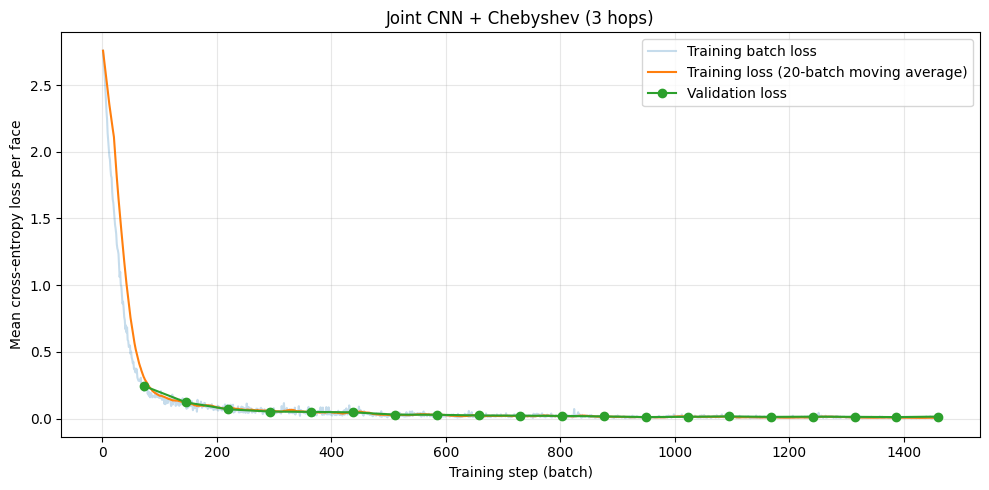

In [69]:
import matplotlib.pyplot as plt
import pandas as pd

batch_log = pd.DataFrame(batch_history)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(batch_log["step"], batch_log["loss"], alpha=0.25, label="Training batch loss")
ax.plot(batch_log["step"], batch_log["loss"].rolling(20, min_periods=1).mean(),
        label="Training loss (20-batch moving average)")
ax.plot([row["step"] for row in history],
        [row["validation_loss"] for row in history], marker="o", label="Validation loss")
ax.set_xlabel("Training step (batch)")
ax.set_ylabel("Mean cross-entropy loss per face")
ax.set_title(f"{training_mode.capitalize()} CNN + Chebyshev ({cheb_hops} hops)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(run_dir / "loss.png", dpi=150)
plt.show()

### 6.2 Accuracy and per-class IoU for the current run

Saved predictions provide loss, accuracy, and intersection over union (IoU)
for all three splits. IoU is `TP / (TP + FP + FN)`, with counts aggregated
across all faces in each split. Mean IoU gives each class equal weight,
includes stock, and excludes classes with zero union.

This report reads cached predictions without inference. After a kernel restart,
run the imports and configuration cells in section 1, then this cell; encoder
loading and graph preparation are not required. All three prediction files must
be available at the selected epoch. Set `report_checkpoint_dir` to inspect another run.

In [70]:
# Choose the saved epoch to analyse.
report_checkpoint_dir = run_dir / f"epoch_{num_epochs:03d}"
for split in SPLITS:
    prediction_path = report_checkpoint_dir / f"{split}_predictions.pt"
    if not prediction_path.is_file():
        raise FileNotFoundError(
            f"Missing {prediction_path}. Run final evaluation for all three splits first."
        )

class_names = {}
for label_file in (DATA_DIR / "labels").glob("*.json"):
    with label_file.open() as file:
        faces = json.load(file)["body"]["faces"]
    for face in faces:
        segment = face["segment"]
        class_names[segment["index"]] = segment["name"]
    if len(class_names) == 16:
        break

class_rows = []
summary_rows = []
for split in SPLITS:
    prediction_path = report_checkpoint_dir / f"{split}_predictions.pt"
    results = torch.load(prediction_path, map_location="cpu", weights_only=True)
    labels = results["labels"].long()
    predictions = results["predictions"].long()
    num_classes = results["probabilities"].shape[1]
    confusion = torch.bincount(
        labels * num_classes + predictions, minlength=num_classes**2
    ).reshape(num_classes, num_classes)
    intersection = confusion.diag()
    union = confusion.sum(1) + confusion.sum(0) - intersection
    # Leave out classes with no true or predicted faces when averaging IoU.
    iou = intersection.double() / union.double().masked_fill(union == 0, float("nan"))
    summary_rows.append({
        "split": split,
        "solids": len(results["sample_ids"]),
        "faces": labels.numel(),
        "loss": results["loss"],
        "accuracy": intersection.sum().item() / labels.numel(),
        "mean_iou": iou.nanmean().item(),
    })
    for index in range(num_classes):
        class_rows.append({
            "split": split, "class_index": index,
            "class_name": class_names.get(index, str(index)),
            "support": confusion[index].sum().item(),
            "intersection": intersection[index].item(),
            "union": union[index].item(), "iou": iou[index].item(),
        })

summary = pd.DataFrame(summary_rows).set_index("split")
per_class_iou = pd.DataFrame(class_rows)
display(summary.style.format({"loss": "{:.4f}", "accuracy": "{:.2%}", "mean_iou": "{:.2%}"}))
display(per_class_iou.pivot(index=["class_index", "class_name"],
                           columns="split", values="iou").style.format("{:.2%}"))
summary.to_csv(report_checkpoint_dir / "iou_summary.csv")
per_class_iou.to_csv(report_checkpoint_dir / "per_class_iou.csv", index=False)

,solids,faces,loss,accuracy,mean_iou
split,,,,,
train,9277,209847,0.0099,99.66%,99.32%
validation,3090,70255,0.0145,99.53%,99.00%
test,3094,69411,0.0187,99.37%,98.76%


,split,test,train,validation
class_index,class_name,,,
0,rectangular_through_slot,99.90%,99.93%,99.46%
1,triangular_through_slot,89.14%,93.62%,90.70%
2,rectangular_passage,97.30%,99.13%,98.10%
3,triangular_passage,94.79%,96.83%,96.26%
4,6sides_passage,99.90%,99.98%,99.95%
5,rectangular_through_step,99.97%,99.99%,99.97%
6,2sides_through_step,99.94%,99.93%,100.00%
7,slanted_through_step,99.93%,99.99%,99.93%
8,rectangular_blind_step,99.94%,99.94%,99.94%


### 6.3 Comparison with geometry-only and Chebyshev variants

Saved predictions are used to compare the geometry-only model and Chebyshev
variants. Hop counts, training modes, and run IDs remain separate. For each
variant, the latest epoch with training and validation exports is selected.
Test scores are included when available at that same epoch, allowing earlier
runs with only training and validation exports to remain visible.

Epoch, loss, accuracy, mean IoU, and per-class metrics are reported without
training or inference. Mean IoU includes stock. This comparison does not select
models by validation or test performance and can run independently after a kernel restart.

In [71]:
# Compare cached final predictions across all completed variants.
import json
import pandas as pd
import torch
from IPython.display import display
from uvnet_project.load_mfcad import DATA_DIR

project_dir = DATA_DIR.parent.parent
import re
variant_dirs = {"Geometry only": project_dir / "results/baseline_run_01"}
for folder in sorted((project_dir / "results").glob("cheb*_run_*")):
    match = re.fullmatch(r"cheb(\d+)_(frozen|joint)_run_(\d+)", folder.name)
    if match:
        hops, mode, run_id = match.groups()
        label = f"{mode.capitalize()} CNN + Chebyshev ({hops} hops, run {run_id})"
        variant_dirs[label] = folder
class_names = {}
for label_file in (DATA_DIR / "labels").glob("*.json"):
    with label_file.open() as file:
        faces = json.load(file)["body"]["faces"]
    for face in faces:
        segment = face["segment"]
        class_names[segment["index"]] = segment["name"]
    if len(class_names) == 16:
        break

summary_rows, class_rows = [], []
for variant, directory in variant_dirs.items():
    # Final predictions are written only after training. Use the highest epoch
    # with both splits available, not a partially written final evaluation.
    completed = [folder for folder in directory.glob("epoch_*")
                 if folder.name.removeprefix("epoch_").isdigit()
                 and all((folder / f"{split}_predictions.pt").is_file()
                         for split in ("train", "validation"))]
    if not completed:
        print(f"No completed prediction files yet: {variant}")
        continue
    checkpoint_dir = max(completed, key=lambda folder: int(folder.name.split("_")[-1]))
    epoch = int(checkpoint_dir.name.split("_")[-1])
    available_splits = [split for split in ("train", "validation", "test")
                        if (checkpoint_dir / f"{split}_predictions.pt").is_file()]
    for split in available_splits:
        results = torch.load(checkpoint_dir / f"{split}_predictions.pt",
                             map_location="cpu", weights_only=True)
        labels, predictions = results["labels"].long(), results["predictions"].long()
        num_classes = results["probabilities"].shape[1]
        confusion = torch.bincount(labels * num_classes + predictions,
                                  minlength=num_classes**2).reshape(num_classes, num_classes)
        intersection = confusion.diag()
        support = confusion.sum(1)
        union = support + confusion.sum(0) - intersection
        iou = intersection.double() / union.double().masked_fill(union == 0, float("nan"))
        per_class_accuracy = intersection.double() / support.double().masked_fill(support == 0, float("nan"))
        summary_rows.append(dict(variant=variant, epoch=epoch, split=split,
                                 faces=labels.numel(), loss=results["loss"],
                                 accuracy=intersection.sum().item() / labels.numel(),
                                 mean_iou=iou.nanmean().item()))
        for index in range(num_classes):
            class_rows.append(dict(variant=variant, epoch=epoch, split=split,
                                   class_index=index, class_name=class_names.get(index, str(index)),
                                   support=support[index].item(), iou=iou[index].item(),
                                   accuracy=per_class_accuracy[index].item()))

if summary_rows:
    summary = pd.DataFrame(summary_rows).set_index(["variant", "epoch", "split"])
    per_class_metrics = pd.DataFrame(class_rows)
    display(summary.style.format({"loss": "{:.4f}", "accuracy": "{:.2%}", "mean_iou": "{:.2%}"}))
    print("Per-class IoU (unweighted class mean above, including stock):")
    display(per_class_metrics.pivot(index=["class_index", "class_name"],
                                    columns=["variant", "split"], values="iou").style.format("{:.2%}"))
    summary.to_csv(project_dir / "results/cheb_variant_metrics.csv")
    per_class_metrics.to_csv(project_dir / "results/cheb_variant_per_class_metrics.csv", index=False)
else:
    print("Run training through final prediction export before comparing metrics.")

Per-class IoU (unweighted class mean above, including stock):


### 6.4 Loss comparison across variants

Epoch-level training and validation losses are read from the saved histories
of the geometry-only model and Chebyshev variants. Two-hop and three-hop filters
and frozen and joint modes remain separate. Missing runs are skipped. Test scores
are not used to construct training curves. This cell can run independently after
a kernel restart.

Saved comparison: C:\Users\KaiSheng\OneDrive\Desktop\GNN-IN-CAD\results\cheb_variants_loss.png


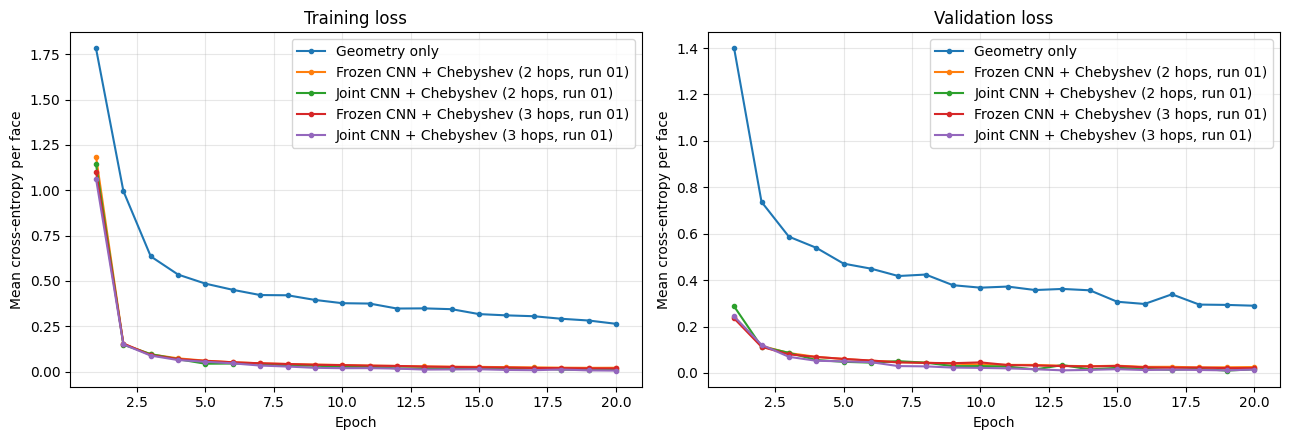

In [72]:
# Comparison from saved histories; no inference or training.
import matplotlib.pyplot as plt
import pandas as pd

import re
from uvnet_project.load_mfcad import DATA_DIR
project_dir = DATA_DIR.parent.parent
variants = {"Geometry only": project_dir / "results/baseline_run_01/history.csv"}
for folder in sorted((project_dir / "results").glob("cheb*_run_*")):
    match = re.fullmatch(r"cheb(\d+)_(frozen|joint)_run_(\d+)", folder.name)
    if match:
        hops, mode, run_id = match.groups()
        label = f"{mode.capitalize()} CNN + Chebyshev ({hops} hops, run {run_id})"
        variants[label] = folder / "history.csv"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plotted = 0
for label, path in variants.items():
    if not path.is_file():
        print(f"Not run yet: {label}")
        continue
    frame = pd.read_csv(path)
    if frame.empty:
        continue
    for ax, metric in zip(axes, ("train_loss", "validation_loss")):
        ax.plot(frame["epoch"], frame[metric], marker="o", markersize=3, label=label)
    plotted += 1
for ax, title in zip(axes, ("Training loss", "Validation loss")):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean cross-entropy per face")
    ax.grid(alpha=0.3)
    if plotted:
        ax.legend()
fig.tight_layout()
if plotted:
    comparison_path = project_dir / "results/cheb_variants_loss.png"
    fig.savefig(comparison_path, dpi=150)
    print("Saved comparison:", comparison_path)
plt.show()